=== Этап 2: Загрузка и исследование данных (EDA) ===
Размерность датасета: (1500, 9)

Информация о пропусках в данных:
patient_id                0
age                      45
gender                    0
drug_class                0
dosage_mg                 0
polypharmacy_count        0
history_of_allergies      0
blood_pressure_status    30
severe_adr                0
dtype: int64


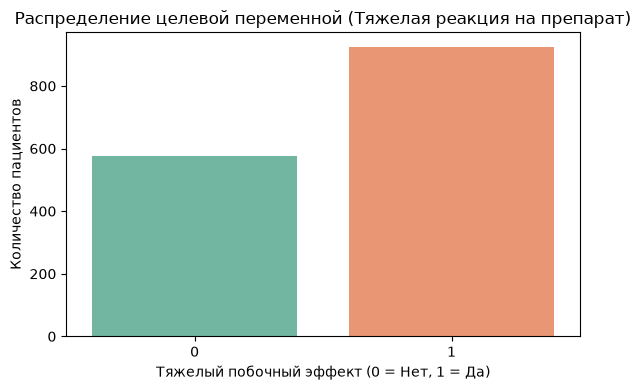

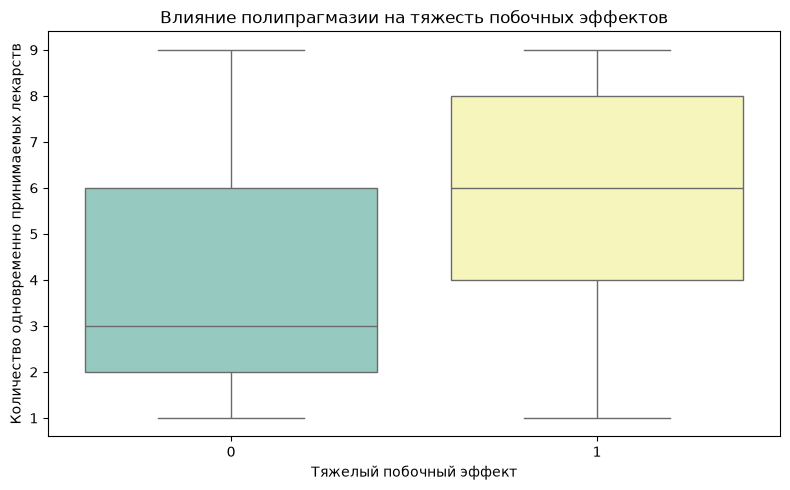

Размер обучающей выборки: 1200, тестовой: 300
Запуск кросс-валидации и оптимизации гиперпараметров для Random Forest...
Лучшие параметры Random Forest: {'classifier__max_depth': 5, 'classifier__min_samples_split': 5, 'classifier__n_estimators': 100}

=== Этап 4: Оценка и интерпретация ===

Метрики для Logistic Regression:
  Accuracy: 0.7100
  Precision: 0.7188
  Recall: 0.8703
  F1-Score: 0.7873
  ROC-AUC: 0.7561

Метрики для Random Forest (Optimized):
  Accuracy: 0.6733
  Precision: 0.6820
  Recall: 0.8811
  F1-Score: 0.7689
  ROC-AUC: 0.7468


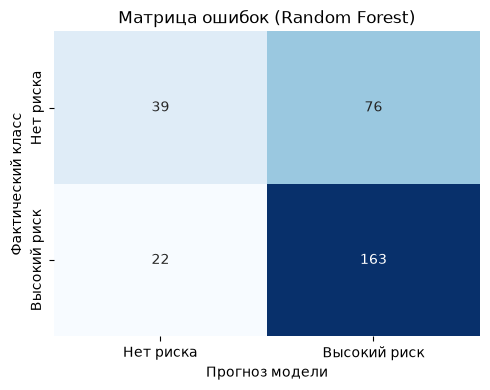

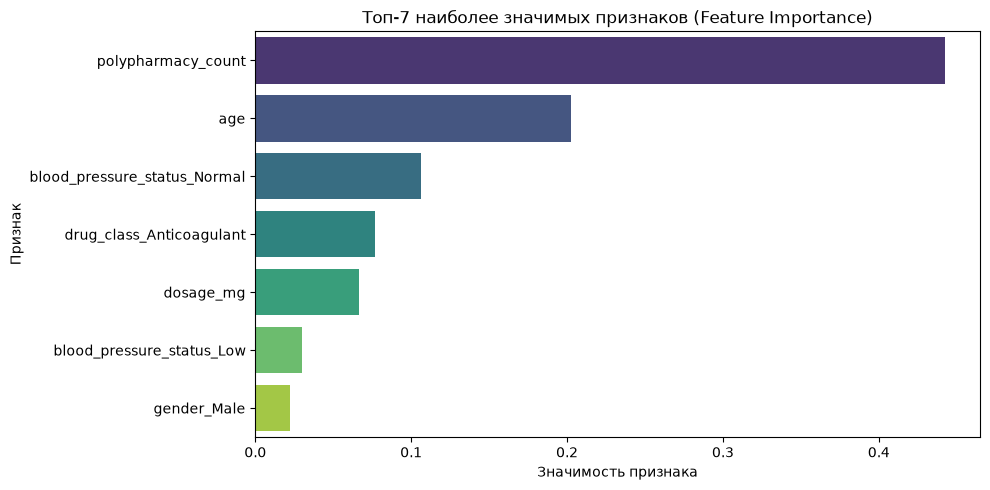


Важность признаков для бизнеса:
                     Feature  Importance
          polypharmacy_count    0.442773
                         age    0.202388
blood_pressure_status_Normal    0.106371
    drug_class_Anticoagulant    0.076606
                   dosage_mg    0.066483
   blood_pressure_status_Low    0.029748
                 gender_Male    0.021993
          drug_class_Statins    0.020246
            drug_class_NSAID    0.018700
drug_class_Antiviral/Vaccine    0.014690


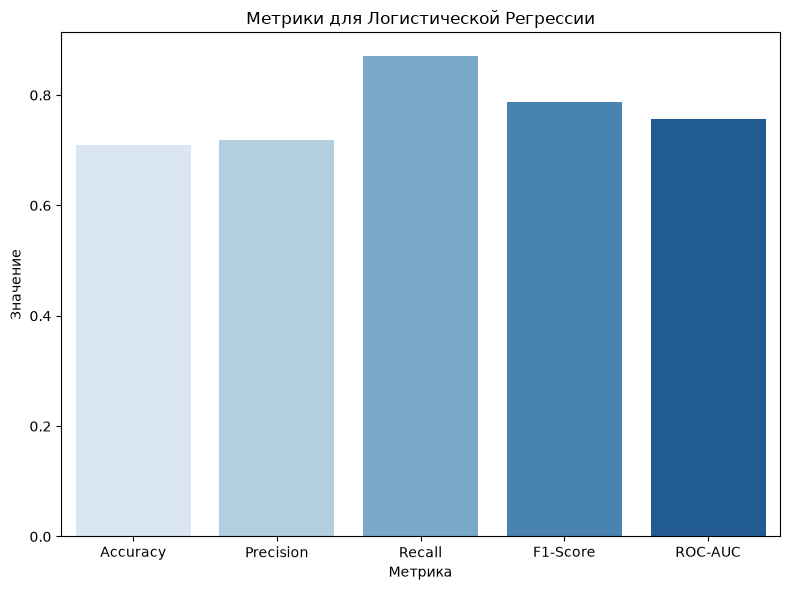

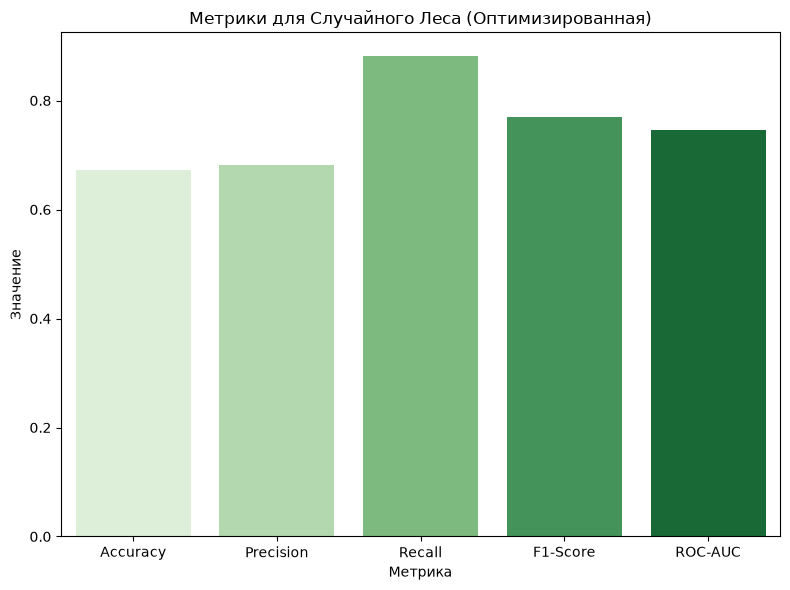


Все графики успешно сохранены!


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report

# 1. Загрузка данных
print("=== Этап 2: Загрузка и исследование данных (EDA) ===")
df = pd.read_csv('adverse_drug_reactions.csv')
print(f"Размерность датасета: {df.shape}")
print("\nИнформация о пропусках в данных:")
print(df.isnull().sum())

# Быстрая визуализация и сохранение графиков для презентации
plt.figure(figsize=(6, 4))
sns.countplot(x='severe_adr', data=df, palette='Set2',hue='severe_adr',legend=False)
plt.title('Распределение целевой переменной (Тяжелая реакция на препарат)')
plt.xlabel('Тяжелый побочный эффект (0 = Нет, 1 = Да)')
plt.ylabel('Количество пациентов')
plt.tight_layout()
plt.savefig('target_distribution.png', dpi=150)
plt.show()

plt.figure(figsize=(8, 5))
sns.boxplot(x='severe_adr', y='polypharmacy_count', data=df, palette='Set3', hue='severe_adr', legend=False)
plt.title('Влияние полипрагмазии на тяжесть побочных эффектов')
plt.xlabel('Тяжелый побочный эффект')
plt.ylabel('Количество одновременно принимаемых лекарств')
plt.tight_layout()
plt.savefig('polypharmacy_impact.png', dpi=150)
plt.show()

# 2. Выделение признаков и целевой переменной
X = df.drop(columns=['patient_id', 'severe_adr'])
y = df['severe_adr']

# Разделение признаков по типам
numeric_features = ['age', 'dosage_mg', 'polypharmacy_count']
categorical_features = ['gender', 'drug_class', 'blood_pressure_status']

# Разделение на обучающую и тестовую выборки (train/test split)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(f"Размер обучающей выборки: {X_train.shape[0]}, тестовой: {X_test.shape[0]}")

# 3. Создание пайплайнов предобработки (Preprocessing Pipelines)
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')), # Заполнение пропусков медианой
    ('scaler', StandardScaler())                  # Стандартизация
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')), # Заполнение пропусков модой
    ('encoder', OneHotEncoder(drop='first', handle_unknown='ignore')) # OHE-кодирование
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ])

# 4. Этап 3: Обучение моделей

# Модель 1: Логистическая регрессия (Baseline)
log_reg_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(random_state=42, max_iter=1000))
])
log_reg_pipeline.fit(X_train, y_train)
y_pred_lr = log_reg_pipeline.predict(X_test)
y_prob_lr = log_reg_pipeline.predict_proba(X_test)[:, 1]

# Модель 2: Случайный лес (Random Forest) с подбором гиперпараметров через GridSearch
rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=42))
])

param_grid_rf = {
    'classifier__n_estimators': [50, 100, 200],
    'classifier__max_depth': [5, 10, None],
    'classifier__min_samples_split': [2, 5]
}

print("Запуск кросс-валидации и оптимизации гиперпараметров для Random Forest...")
grid_search_rf = GridSearchCV(rf_pipeline, param_grid_rf, cv=5, scoring='f1', n_jobs=-1)
grid_search_rf.fit(X_train, y_train)
best_rf_model = grid_search_rf.best_estimator_

y_pred_rf = best_rf_model.predict(X_test)
y_prob_rf = best_rf_model.predict_proba(X_test)[:, 1]

print(f"Лучшие параметры Random Forest: {grid_search_rf.best_params_}")

# 5. Этап 4: Оценка и сравнение моделей
print("\n=== Этап 4: Оценка и интерпретация ===")

def evaluate_model(y_true, y_pred, y_prob, model_name):
    metrics = {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred),
        'Recall': recall_score(y_true, y_pred),
        'F1-Score': f1_score(y_true, y_pred),
        'ROC-AUC': roc_auc_score(y_true, y_prob)
    }
    print(f"\nМетрики для {model_name}:")
    for k, v in metrics.items():
        print(f"  {k}: {v:.4f}")
    return metrics

lr_metrics = evaluate_model(y_test, y_pred_lr, y_prob_lr, "Logistic Regression")
rf_metrics = evaluate_model(y_test, y_pred_rf, y_prob_rf, "Random Forest (Optimized)")

# Матрица ошибок лучшей модели (Random Forest)
plt.figure(figsize=(5, 4))
cm = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Нет риска', 'Высокий риск'], yticklabels=['Нет риска', 'Высокий риск'])
plt.title('Матрица ошибок (Random Forest)')
plt.ylabel('Фактический класс')
plt.xlabel('Прогноз модели')
plt.tight_layout()
plt.savefig('confusion_matrix_best.png', dpi=150)
plt.show()

# Извлечение важности признаков из Random Forest
classifier_step = best_rf_model.named_steps['classifier']
encoder_step = best_rf_model.named_steps['preprocessor'].named_transformers_['cat'].named_steps['encoder']

cat_features_transformed = encoder_step.get_feature_names_out(categorical_features).tolist()
all_features = numeric_features + cat_features_transformed
importances = classifier_step.feature_importances_

feature_imp_df = pd.DataFrame({'Feature': all_features, 'Importance': importances}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(x='Importance', y='Feature', data=feature_imp_df.head(7),hue='Feature', legend=False, palette='viridis')
plt.title('Топ-7 наиболее значимых признаков (Feature Importance)')
plt.xlabel('Значимость признака')
plt.ylabel('Признак')
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=150)
plt.show()

print("\nВажность признаков для бизнеса:")
print(feature_imp_df.to_string(index=False))

# 5.2. Визуализация оценки моделей
plt.figure(figsize=(8, 6))
sns.barplot(x=list(lr_metrics.keys()), y=[lr_metrics[k] for k in lr_metrics], hue=list(lr_metrics.keys()), legend=False, palette='Blues')
plt.title('Метрики для Логистической Регрессии')
plt.xlabel('Метрика')
plt.ylabel('Значение')
plt.tight_layout()
plt.savefig('log_reg_metrics.png', dpi=150)
plt.show()

plt.figure(figsize=(8, 6))
sns.barplot(x=list(rf_metrics.keys()), y=[rf_metrics[k] for k in rf_metrics],hue=list(lr_metrics.keys()), legend=False, palette='Greens')
plt.title('Метрики для Случайного Леса (Оптимизированная)')
plt.xlabel('Метрика')
plt.ylabel('Значение')
plt.tight_layout()
plt.savefig('rf_metrics.png', dpi=150)
plt.show()

print("\nВсе графики успешно сохранены!")
